# Комп'ютерний практикум № 4. Дослідження DQN у середовищі Acrobot-v1

**Метод:** Deep Q-Network (DQN). **Реалізація:** Stable-Baselines3 (`stable_baselines3.DQN`). **Середовище:** Gymnasium `Acrobot-v1`.

**Джерела**
* Реалізація: Stable-Baselines3 — https://github.com/DLR-RM/stable-baselines3 (документація DQN: https://stable-baselines3.readthedocs.io/en/master/modules/dqn.html).
* Базові гіперпараметри: RL Baselines3 Zoo, `hyperparams/dqn.yml`, запис `Acrobot-v1` — https://github.com/DLR-RM/rl-baselines3-zoo; ті самі значення наведено в картці навченої моделі https://huggingface.co/sb3/dqn-Acrobot-v1.
* Середовище: https://gymnasium.farama.org/environments/classic_control/acrobot/.
* Метод: Mnih et al., *Human-level control through deep reinforcement learning*, Nature 518, 2015.

**Власні зміни:** код алгоритму не змінювався. Самостійно реалізовано скрипт експериментів `cw4_experiments.py` (серії з одним зміненим гіперпараметром, по 3 seed; журнал навчальних епізодів через `Monitor`; періодичне детерміноване оцінювання через `EvalCallback`; фінальне оцінювання на 50 епізодах з фіксованими seed) і цей ноутбук аналізу (графіки, таблиці, демонстрація поведінки, аналіз Q-значень). Бюджет навчання скорочено з 100 000 до 60 000 кроків через обмежені ресурси CPU.

Експерименти запускаються командою `python cw4_experiments.py --workers 2` (≈ 40 хв на 2 ядрах CPU). Ноутбук читає збережені результати з папки `results/`; щоб перерахувати все з нуля, достатньо видалити цю папку і встановити `RUN_EXPERIMENTS = True`.

In [1]:
import os, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from stable_baselines3 import DQN
from IPython.display import display, Image

import cw4_experiments as X

RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    import subprocess; subprocess.run(["python", "cw4_experiments.py", "--workers", "2"], check=True)

torch.set_num_threads(1)
pd.set_option("display.precision", 2)
print("Конфігурацій:", len(X.CONFIGS), "| seed:", X.SEEDS, "| кроків на запуск:", X.N_TIMESTEPS)

Конфігурацій: 9 | seed: [0, 1, 2] | кроків на запуск: 60000


## 1. Задача та середовище

**Acrobot** — дволанковий маятник («гімнаст на турніку»): верхня ланка закріплена шарніром, привод є лише в шарнірі між ланками (*недоактуована* система). Мета — розгойдати систему так, щоб кінець нижньої ланки піднявся вище заданого рівня.

| Елемент | Опис |
|---|---|
| Спостереження | вектор із 6 неперервних чисел: $\cos\theta_1,\sin\theta_1,\cos\theta_2,\sin\theta_2,\dot\theta_1\in[-4\pi,4\pi],\dot\theta_2\in[-9\pi,9\pi]$ |
| Дії | 3 дискретні: момент $-1$, $0$, $+1$ Н·м у середньому шарнірі |
| Винагорода | $-1$ за кожен крок, поки ціль не досягнута; при досягненні цілі — $0$ |
| Завершення (terminated) | висота кінця $-\cos\theta_1-\cos(\theta_1+\theta_2)>1$ |
| Обрізання (truncated) | 500 кроків (ліміт `TimeLimit`) |
| Критерій якості | середній дохід за епізод (більше — краще; $-500$ — агент не досяг цілі); поріг «розв'язано» в Gymnasium — $-100$ |

Винагорода заохочує досягати цілі **якомога швидше**: дохід = $-$(кількість кроків до цілі). Вона повністю відповідає меті задачі, але розріджена: доки агент випадково не підніме кінець ланки, всі епізоди дають однакові $-500$.

In [2]:
env = gym.make("Acrobot-v1")
print("observation_space:", env.observation_space)
print("action_space:", env.action_space, "| reward_threshold:", env.spec.reward_threshold, "| max_episode_steps:", env.spec.max_episode_steps)

# Еталон: випадкова політика
rets = []
for i in range(20):
    obs, _ = env.reset(seed=i); done, R = False, 0
    while not done:
        obs, r, term, trunc, _ = env.step(env.action_space.sample()); R += r; done = term or trunc
    rets.append(R)
print(f"Випадкова політика (20 епізодів): середній дохід {np.mean(rets):.1f}, мін {np.min(rets):.0f}, макс {np.max(rets):.0f}")

observation_space: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
action_space: Discrete(3) | reward_threshold: -100.0 | max_episode_steps: 500


Випадкова політика (20 епізодів): середній дохід -500.0, мін -500, макс -500


## 2. Метод DQN

DQN — **value-based, model-free, off-policy** метод: нейромережа $Q_\theta(s,a)$ апроксимує оптимальну функцію цінності дій, а політика — жадібна за $Q_\theta$ (під час навчання — $\varepsilon$-жадібна). Це табличний Q-learning з КП3, у якому таблицю замінено мережею, а для стійкості додано два механізми:

1. **Буфер відтворення (replay buffer)** — останні `buffer_size` переходів $(s,a,r,s',\text{terminated})$; для кожного оновлення вибирається випадковий батч. Це руйнує кореляцію послідовних кроків і дозволяє багаторазово використовувати досвід (можливо, бо метод off-policy).
2. **Цільова мережа** $Q_{\theta^-}$ — копія основної, яка оновлюється рідко (кожні `target_update_interval` кроків, $\theta^-\leftarrow\theta$). Вона робить ціль оновлення стабільнішою.

Ціль і функція втрат для батча $B$:
$$y=r+\gamma\,(1-\text{terminated})\max_{a'}Q_{\theta^-}(s',a'),\qquad L(\theta)=\frac1{|B|}\sum_{B}\ell_\delta\big(Q_\theta(s,a)-y\big),$$
де $\ell_\delta$ — функція Хубера (`smooth_l1_loss` у SB3). Параметри оновлюються оптимізатором Adam з кроком `learning_rate`, норма градієнта обмежується значенням 10. Обрізання за часом (`truncated`) не обнуляє $\max Q$ у цілі — SB3 враховує це через `timeout`-інформацію.

**Дослідження:** $\varepsilon$ лінійно зменшується від 1.0 до `exploration_final_eps` протягом частки `exploration_fraction` усього навчання, далі лишається сталим. **Оцінювання** виконується детерміновано (жадібно, $\varepsilon=0$).

**Цикл навчання SB3:** кожні `train_freq=4` кроки середовища виконується `gradient_steps` оновлень (тут $-1$ — стільки, скільки зроблено кроків, тобто 4); кожні `target_update_interval` кроків — копіювання ваг у цільову мережу.

## 3. Нейромережева архітектура

`MlpPolicy` DQN містить дві однакові мережі **Q-net** і **Q-net target**. Вхід — 6-вимірний вектор спостереження (без нормалізації), вихід — 3 числа $Q(s,a)$ для кожної дії. Базова конфігурація: два приховані повнозв'язні шари по 256 нейронів з ReLU, вихідний шар лінійний (Q-значення можуть бути будь-якими дійсними, тут — від'ємними).

In [3]:
m = DQN("MlpPolicy", env, policy_kwargs=dict(net_arch=[256, 256]), seed=0, verbose=0)
print(m.policy)
for name, arch in [("net_16", [16]), ("net_64x64", [64, 64]), ("base", [256, 256])]:
    mm = DQN("MlpPolicy", env, policy_kwargs=dict(net_arch=arch), verbose=0)
    print(f"{name:10s} net_arch={str(arch):11s} параметрів Q-мережі: {sum(p.numel() for p in mm.q_net.parameters()):,}")

DQNPolicy(
  (q_net): QNetwork(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (q_net): Sequential(
      (0): Linear(in_features=6, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=3, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (q_net): Sequential(
      (0): Linear(in_features=6, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=3, bias=True)
    )
  )
)
net_16     net_arch=[16]        параметрів Q-мережі: 163
net_64x64  net_arch=[64, 64]    параметрів Q-мережі: 4,803
base       net_arch=[256, 256]  параметрів Q-мережі: 68,355


## 4. Експерименти

### Базова конфігурація (RL Zoo) та план

| Гіперпараметр | Значення | Роль |
|---|---|---|
| `learning_rate` | 6.3e-4 | крок Adam |
| `batch_size` | 128 | розмір батча з буфера |
| `buffer_size` | 50 000 | обсяг буфера відтворення |
| `learning_starts` | 0 | навчання з першого кроку |
| `gamma` | 0.99 | дисконтування |
| `target_update_interval` | 250 | період копіювання ваг у цільову мережу (кроків) |
| `train_freq`, `gradient_steps` | 4, −1 | 4 оновлення на кожні 4 кроки |
| `exploration_fraction`, `exploration_final_eps` | 0.12, 0.1 | $\varepsilon$: 1 → 0.1 за перші 12 % кроків |
| `net_arch` | [256, 256] | архітектура Q-мережі |

Кожен експеримент змінює **один** гіперпараметр; 3 seed на конфігурацію; 60 000 кроків; оцінювання кожні 3 000 кроків (10 жадібних епізодів) і фінальне — 50 епізодів з фіксованими seed.

| Група | Варіанти | Що перевіряємо |
|---|---|---|
| Крок навчання | 1e-4, **6.3e-4**, 3e-3 | швидкість vs стійкість оновлень мережі |
| Цільова мережа | 10, **250**, 2000 кроків | роль «заморожування» цілі |
| Архітектура | [16], [64, 64], **[256, 256]** | чи вистачає ємності апроксиматора |
| Дослідження | **(0.12, 0.1)**, `exploration_fraction=0.5`, `exploration_final_eps=0.01` | тривалість і рівень $\varepsilon$ |

In [4]:
ROOT = "results"
GROUPS = {
    "Крок навчання": ["lr_1e-4", "base", "lr_3e-3"],
    "Цільова мережа": ["target_10", "base", "target_2000"],
    "Архітектура": ["net_16", "net_64x64", "base"],
    "Дослідження": ["base", "explore_0.5", "eps_end_0.01"],
}
LABELS = {"base": "базова", "lr_1e-4": "lr=1e-4", "lr_3e-3": "lr=3e-3", "target_10": "target=10",
          "target_2000": "target=2000", "net_16": "[16]", "net_64x64": "[64,64]",
          "explore_0.5": "expl.frac=0.5", "eps_end_0.01": "ε_final=0.01"}

runs = {}
for path in sorted(glob.glob(f"{ROOT}/*/final.json")):
    d = os.path.dirname(path)
    fin = json.load(open(path))
    ev = np.load(os.path.join(d, "evaluations.npz"))
    mon = pd.read_csv(os.path.join(d, "monitor.monitor.csv"), skiprows=1)
    runs[(fin["config"], fin["seed"])] = dict(final=fin, eval_t=ev["timesteps"], eval_r=ev["results"].mean(1),
                                              mon=mon)
print("Завантажено запусків:", len(runs))

Завантажено запусків: 27


In [5]:
rows = []
for cfg in X.CONFIGS:
    seeds = [s for s in X.SEEDS if (cfg, s) in runs]
    if not seeds:
        continue
    finals = [np.mean(runs[(cfg, s)]["final"]["final_returns"]) for s in seeds]
    succ = [np.mean(np.array(runs[(cfg, s)]["final"]["final_lengths"]) < 500) for s in seeds]
    # «швидкість»: перший крок, на якому оцінка перевищила -100
    t_solve = []
    for s in seeds:
        r = runs[(cfg, s)]; idx = np.flatnonzero(r["eval_r"] > -100)
        t_solve.append(r["eval_t"][idx[0]] if len(idx) else np.nan)
    # стабільність: середнє і std оцінок на останніх 5 точках (останні 15 000 кроків)
    tail = [runs[(cfg, s)]["eval_r"][-5:] for s in seeds]
    rows.append({"конфігурація": LABELS[cfg], "cfg": cfg, "запусків": len(seeds),
                 "фін. дохід (сер. за seed)": np.mean(finals), "std між seed": np.std(finals),
                 "найгірший seed": np.min(finals), "успішних епізодів": np.mean(succ),
                 "крок досягнення −100": np.nanmean(t_solve) if not np.all(np.isnan(t_solve)) else np.nan,
                 "seed, що досягли −100": int(np.sum(~np.isnan(t_solve))),
                 "коливання оцінки (ост. 15k)": np.mean([np.std(t) for t in tail]),
                 "час, с": np.mean([runs[(cfg, s)]["final"]["train_time_s"] for s in seeds]),
                 "параметрів": runs[(cfg, seeds[0])]["final"]["q_net_params"]})
summary = pd.DataFrame(rows)
display(summary.drop(columns="cfg").style.hide(axis="index").format({
    "фін. дохід (сер. за seed)": "{:.1f}", "std між seed": "{:.1f}", "найгірший seed": "{:.1f}",
    "успішних епізодів": "{:.0%}", "крок досягнення −100": "{:,.0f}", "коливання оцінки (ост. 15k)": "{:.1f}",
    "час, с": "{:.0f}", "параметрів": "{:,}"}))
summary.to_csv("cw4_summary.csv", index=False)

конфігурація,запусків,фін. дохід (сер. за seed),std між seed,найгірший seed,успішних епізодів,крок досягнення −100,"seed, що досягли −100",коливання оцінки (ост. 15k),"час, с",параметрів
базова,3,-78.0,2.7,-81.9,100%,"30,000",3,19.0,236,"68,355"
lr=1e-4,3,-83.0,3.2,-85.5,100%,"25,000",3,29.4,208,"68,355"
lr=3e-3,3,-77.4,3.7,-81.6,100%,"22,000",3,34.9,203,"68,355"
target=10,3,-83.6,2.8,-87.1,100%,"20,000",3,85.1,179,"68,355"
target=2000,3,-499.2,1.1,-500.0,1%,nan,0,45.8,197,"68,355"
[16],3,-420.7,112.1,-500.0,33%,"16,500",2,117.7,79,163
"[64,64]",3,-80.0,2.4,-82.9,100%,"14,000",3,11.2,98,"4,803"
expl.frac=0.5,3,-96.3,26.7,-134.0,96%,"19,000",3,5.9,188,"68,355"
ε_final=0.01,3,-135.3,78.2,-245.9,87%,"26,000",3,16.1,186,"68,355"


**Показники:** *фінальний дохід* — середнє за 50 тестовими епізодами (жадібна політика, фіксовані seed), усереднене за 3 seed навчання; *std між seed* і *найгірший seed* — стійкість результату до випадковості навчання; *успішних епізодів* — частка тестових епізодів, у яких ціль досягнуто до 500 кроків; *крок досягнення −100* — перша оцінка (10 епізодів) вище порогу розв'язання; *коливання оцінки* — середнє std останніх 5 оцінок одного запуску (стабільність наприкінці навчання). *Час* — орієнтовний: запуски йшли паралельно по два на 2 ядрах CPU, тож абсолютні значення залежать від завантаження; порівнювати варто лише порядок величин (мала мережа — помітно швидша).

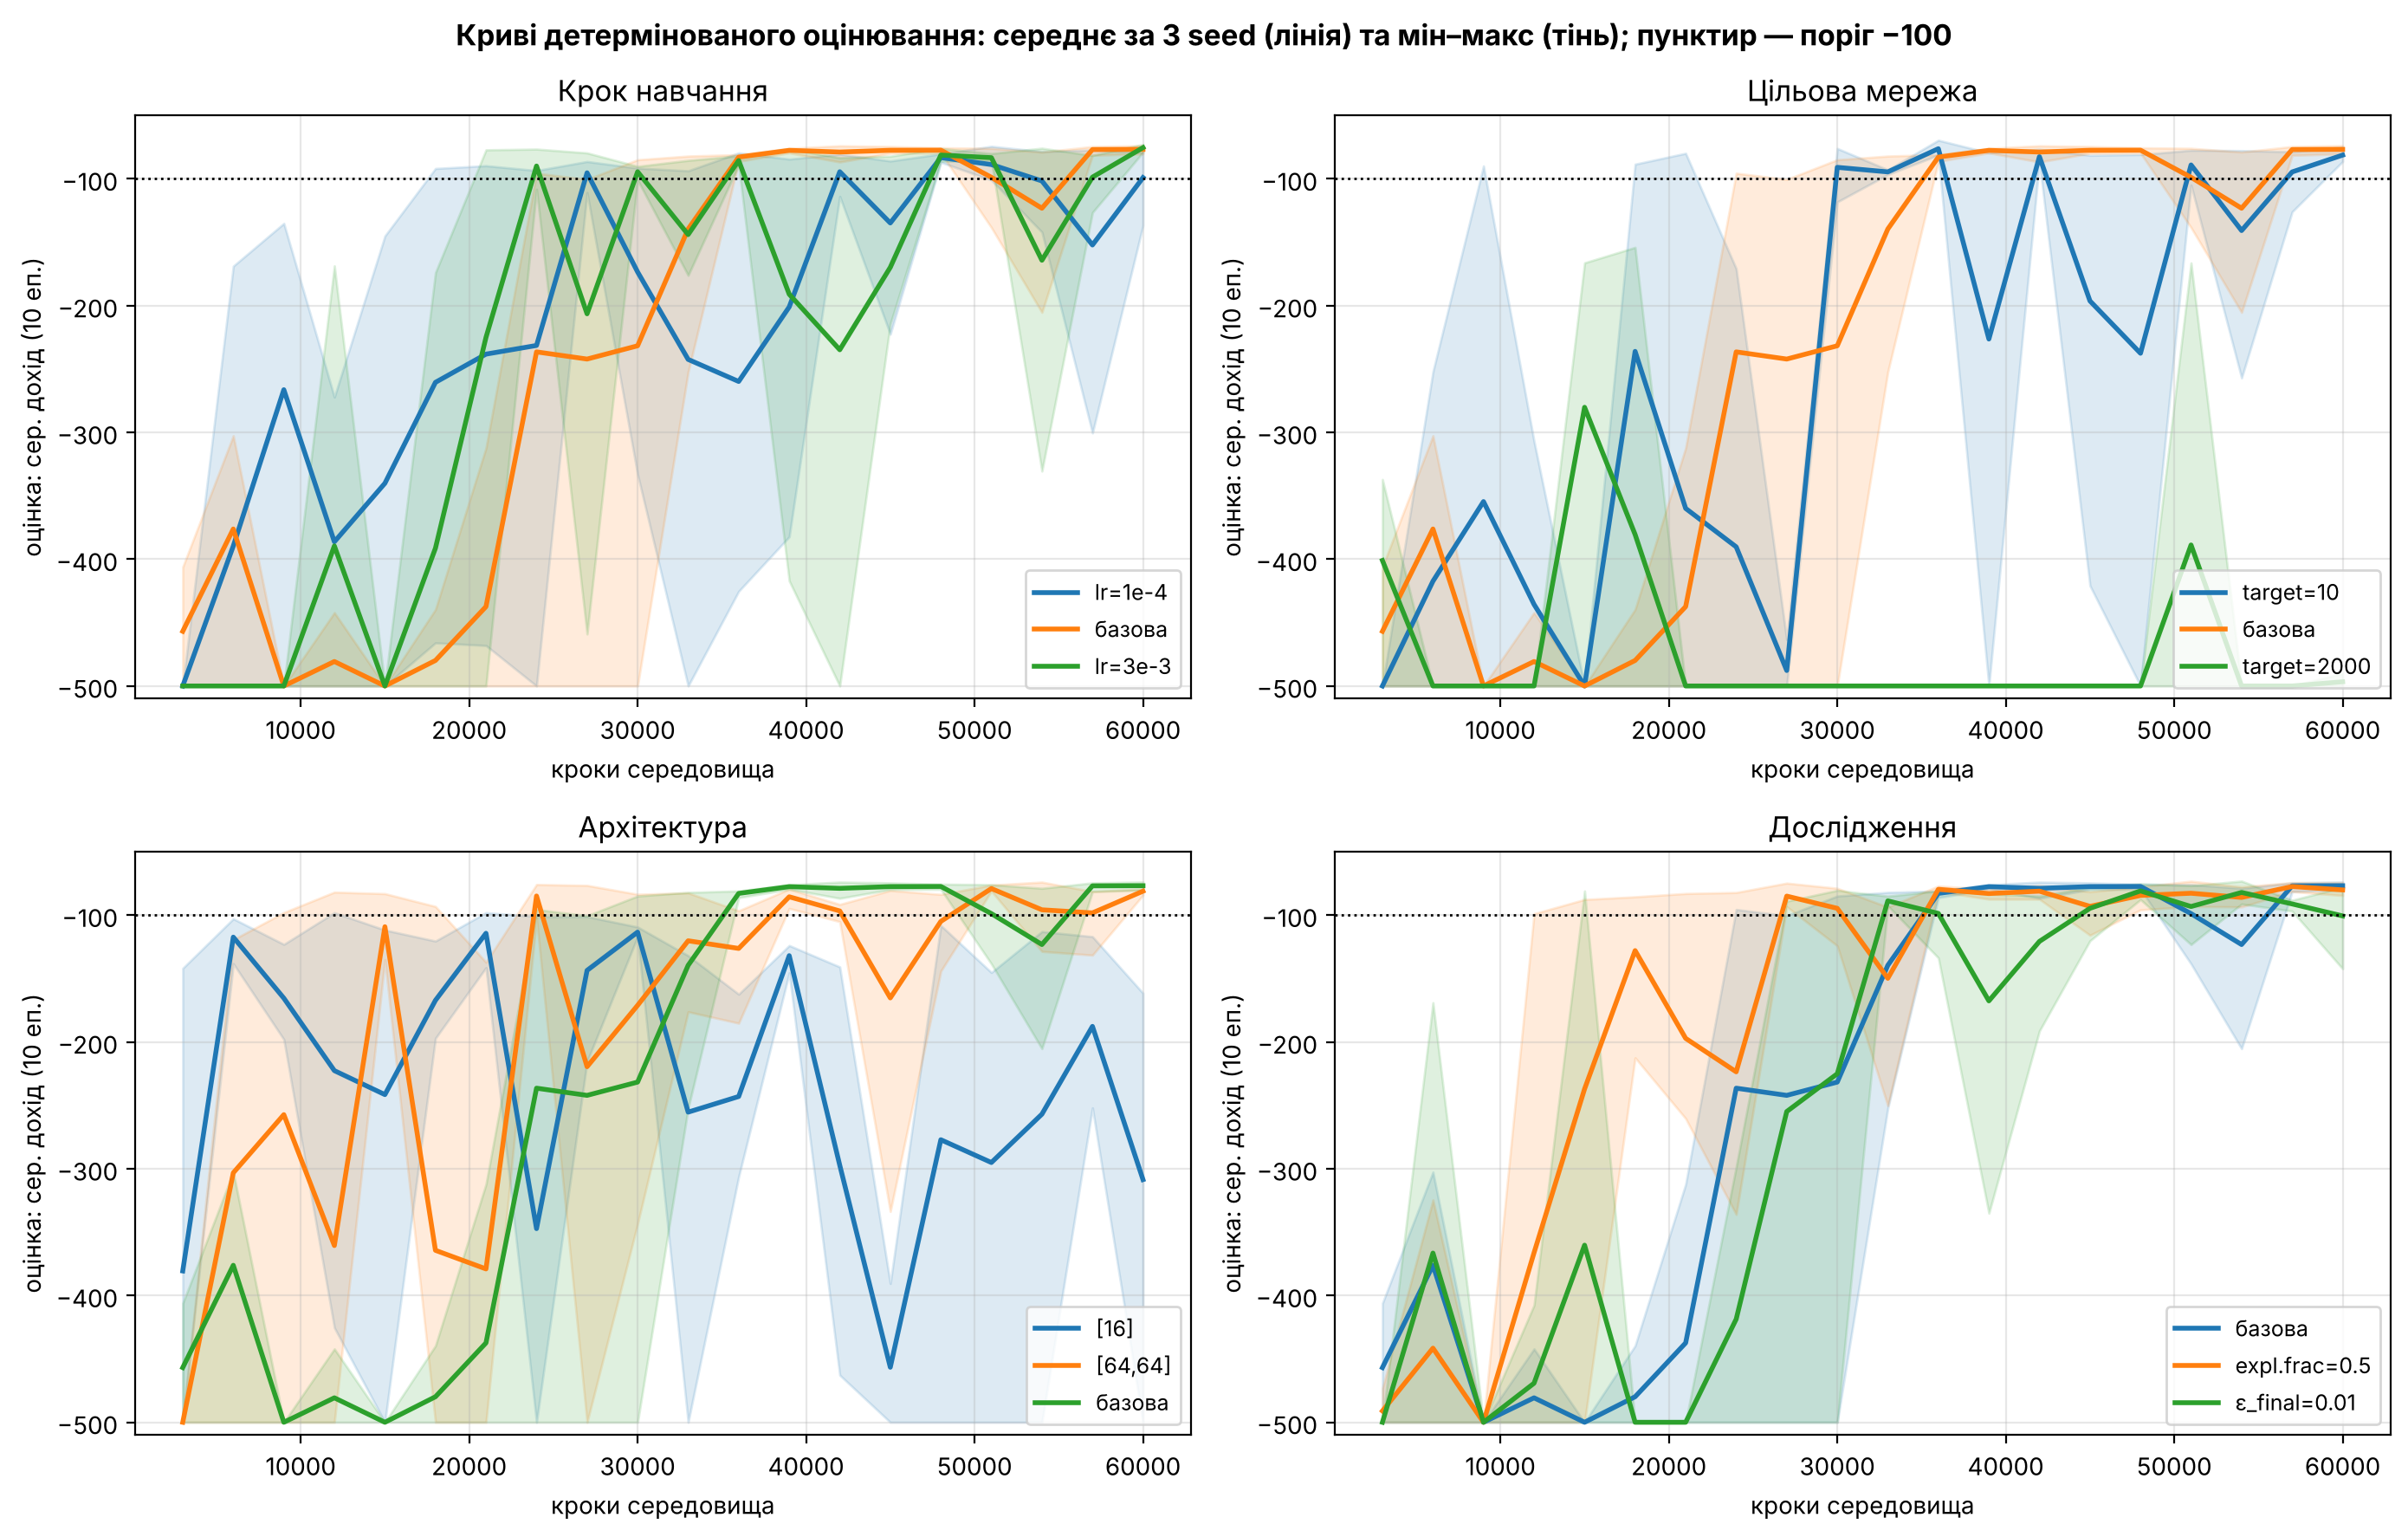

In [6]:
def plot_group(ax, cfgs, title):
    for i, cfg in enumerate(cfgs):
        seeds = [s for s in X.SEEDS if (cfg, s) in runs]
        if not seeds: continue
        t = runs[(cfg, seeds[0])]["eval_t"]
        R = np.array([runs[(cfg, s)]["eval_r"][:len(t)] for s in seeds])
        ax.plot(t, R.mean(0), lw=2, color=f"C{i}", label=LABELS[cfg] + (" (базова)" if cfg == "base" and LABELS[cfg] != "базова" else ""))
        ax.fill_between(t, R.min(0), R.max(0), color=f"C{i}", alpha=0.15)
    ax.axhline(-100, color='k', ls=':', lw=1)
    ax.set_title(title); ax.set_xlabel("кроки середовища"); ax.set_ylabel("оцінка: сер. дохід (10 еп.)")
    ax.set_ylim(-510, -50); ax.grid(alpha=.3); ax.legend(fontsize=9, loc="lower right")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (g, cfgs) in zip(axes.ravel(), GROUPS.items()):
    plot_group(ax, cfgs, g)
plt.suptitle("Криві детермінованого оцінювання: середнє за 3 seed (лінія) та мін–макс (тінь); пунктир — поріг −100",
             fontweight="bold")
plt.tight_layout(); plt.savefig("fig_eval_curves.png", dpi=130, bbox_inches="tight"); plt.show()

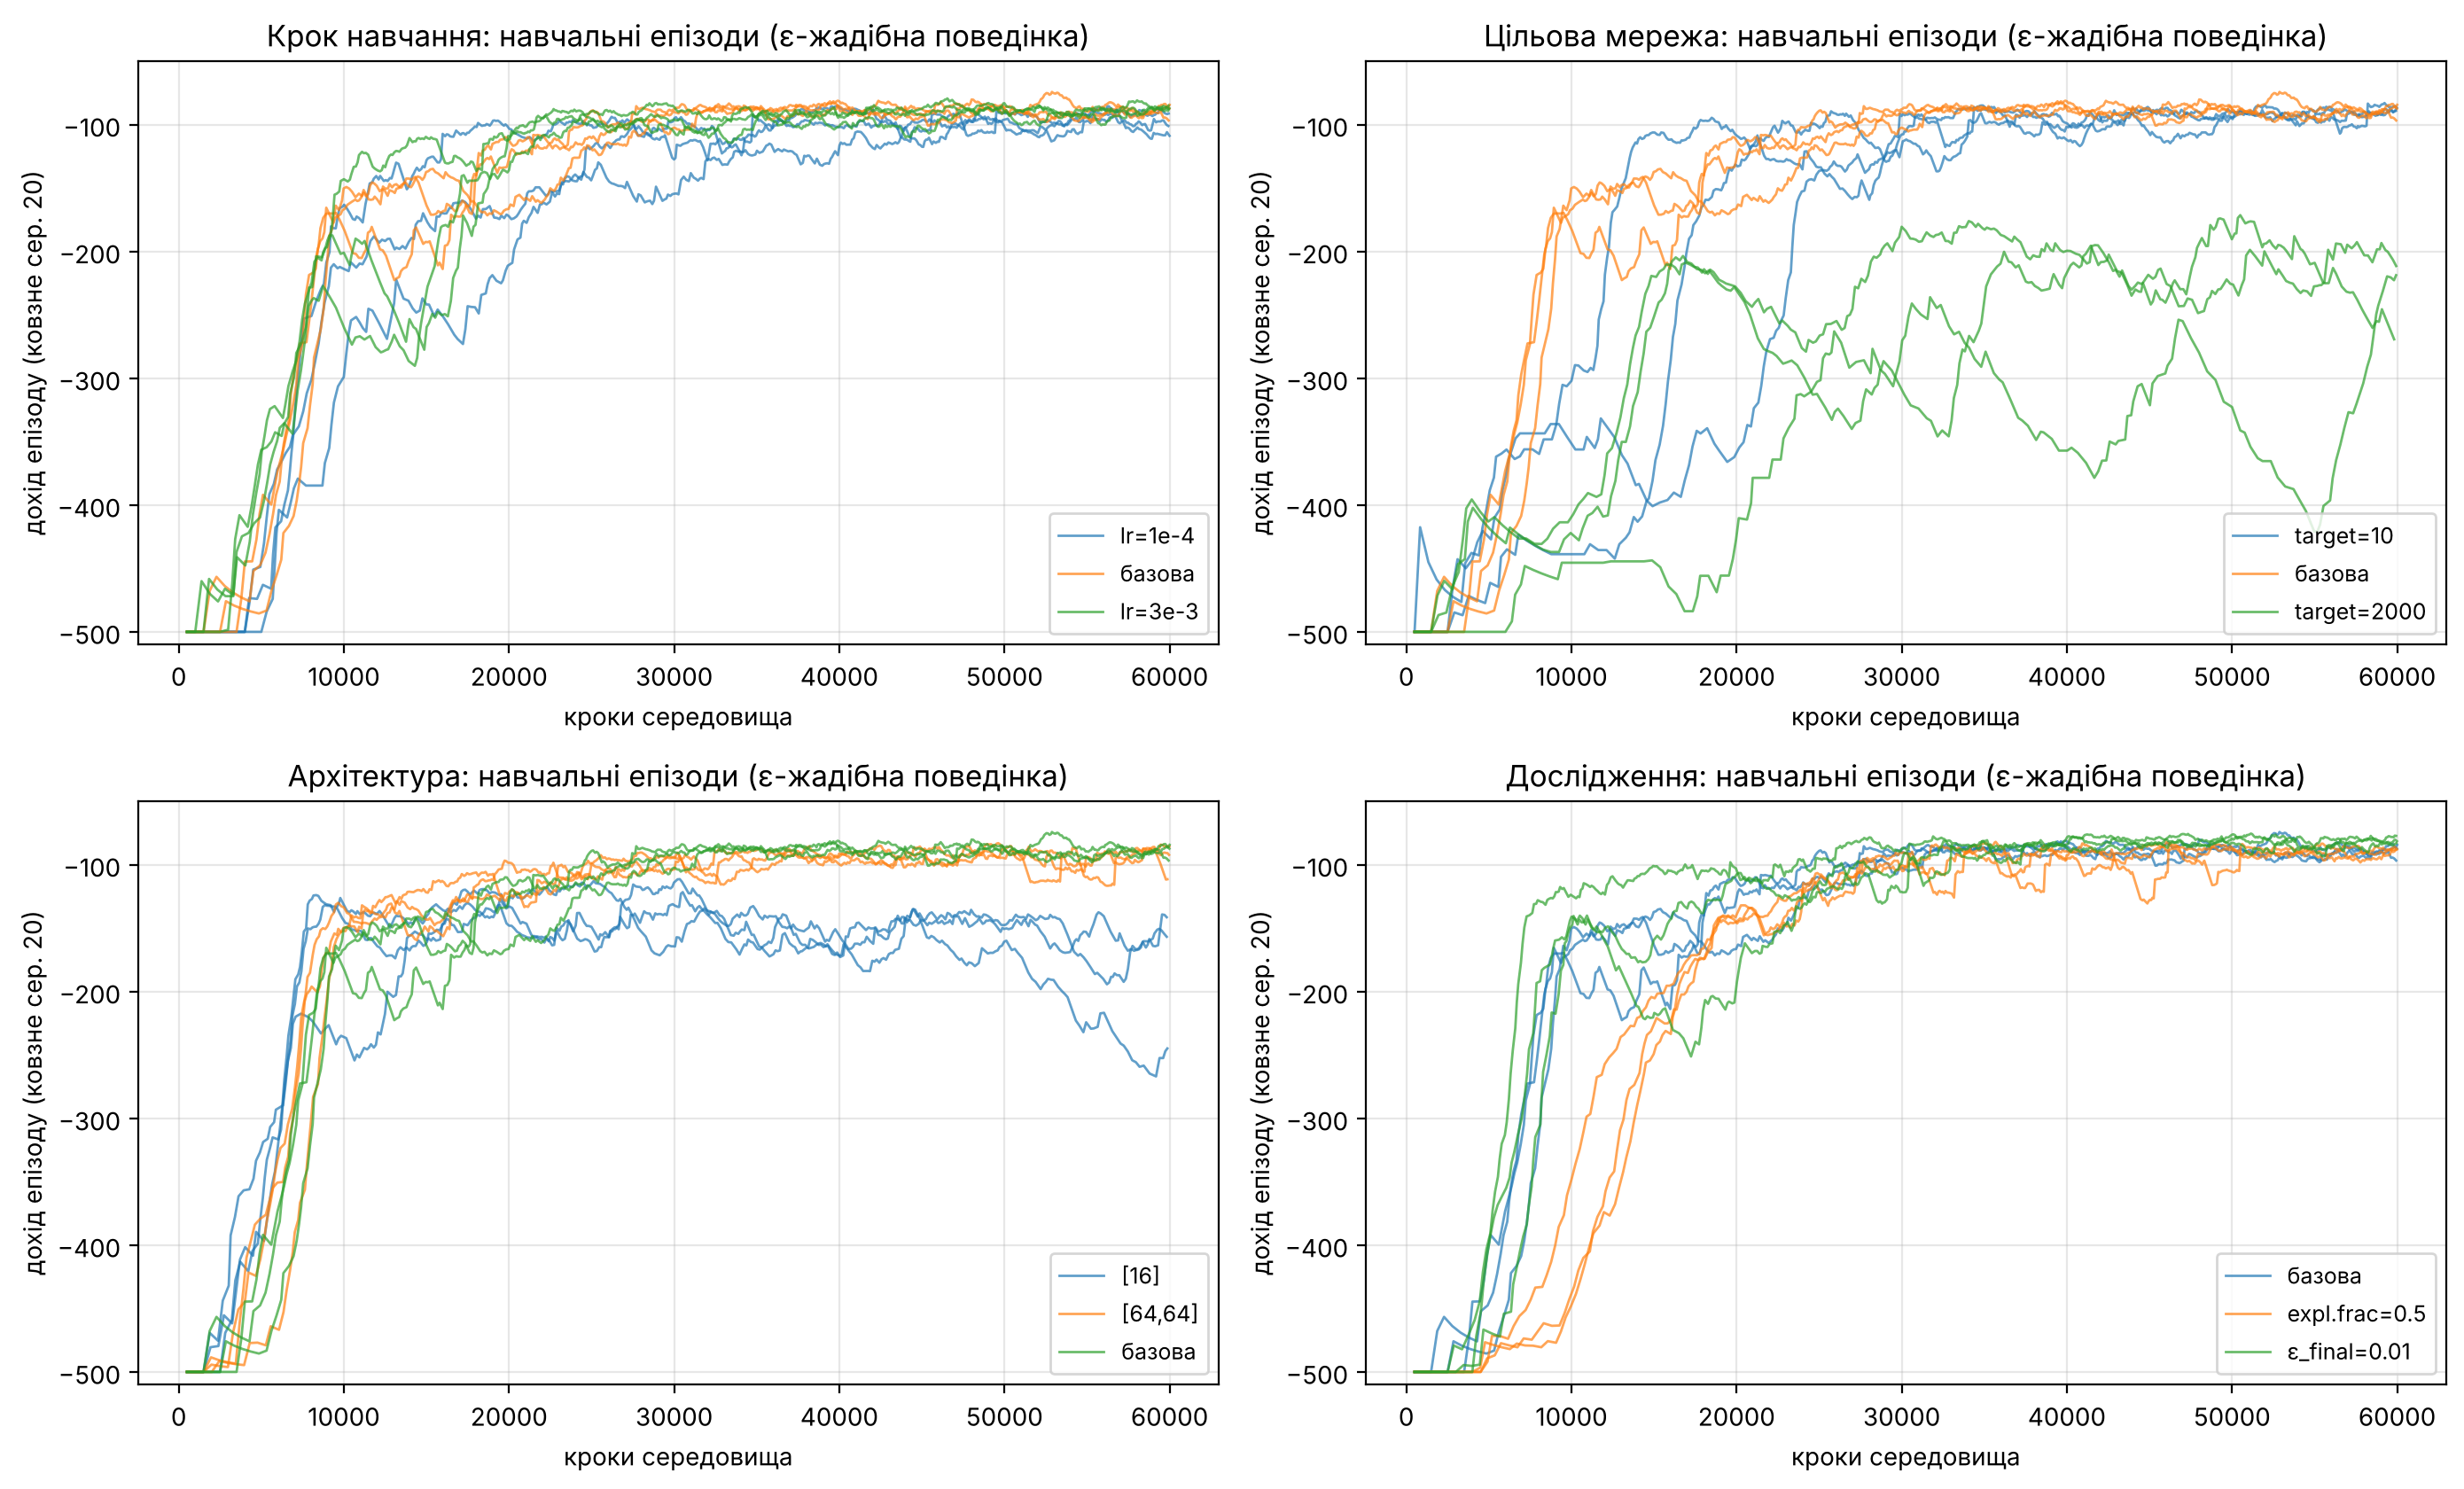

In [7]:
def smooth(x, w=20):
    x = np.asarray(x, float); c = np.r_[0, np.cumsum(x)]; k = np.arange(1, len(x) + 1)
    return (c[k] - c[np.maximum(k - w, 0)]) / (k - np.maximum(k - w, 0))

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for ax, (g, cfgs) in zip(axes.ravel(), GROUPS.items()):
    for i, cfg in enumerate(cfgs):
        for s in X.SEEDS:
            if (cfg, s) not in runs: continue
            mon = runs[(cfg, s)]["mon"]
            ax.plot(np.cumsum(mon.l), smooth(mon.r), color=f"C{i}", alpha=0.7, lw=1,
                    label=LABELS[cfg] if s == 0 else None)
    ax.set_title(f"{g}: навчальні епізоди (ε-жадібна поведінка)"); ax.set_xlabel("кроки середовища")
    ax.set_ylabel("дохід епізоду (ковзне сер. 20)"); ax.set_ylim(-510, -50); ax.grid(alpha=.3); ax.legend(fontsize=9, loc="lower right")
plt.tight_layout(); plt.savefig("fig_train_curves.png", dpi=130, bbox_inches="tight"); plt.show()

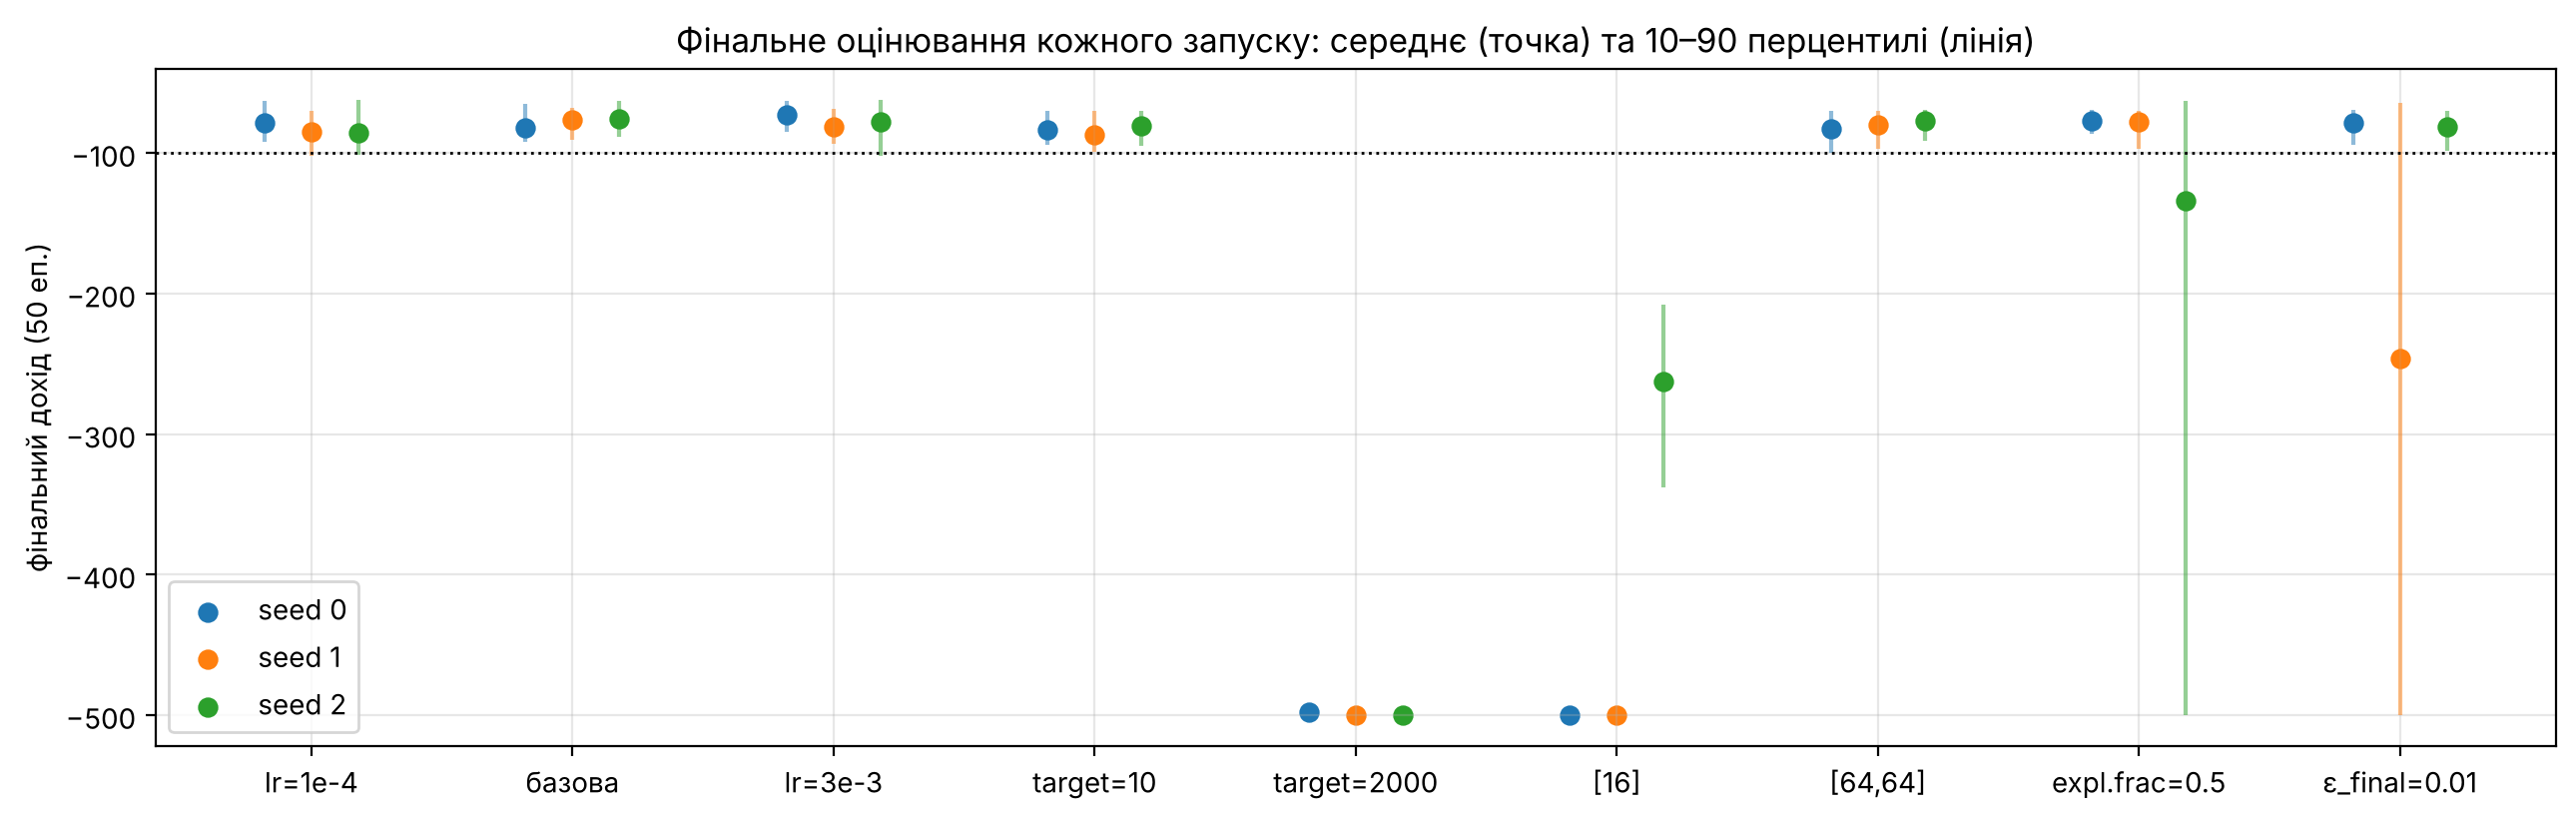

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.2))
order = [c for g in GROUPS.values() for c in g]
order = list(dict.fromkeys(order))
for i, cfg in enumerate(order):
    for s in X.SEEDS:
        if (cfg, s) in runs:
            rr = runs[(cfg, s)]["final"]["final_returns"]
            ax.scatter(i + (s - 1) * 0.18, np.mean(rr), color=f"C{s}", s=40, label=f"seed {s}" if i == 0 else None)
            ax.vlines(i + (s - 1) * 0.18, np.percentile(rr, 10), np.percentile(rr, 90), color=f"C{s}", alpha=.5)
ax.set_xticks(range(len(order))); ax.set_xticklabels([LABELS[c] for c in order])
ax.axhline(-100, color='k', ls=':', lw=1); ax.set_ylabel("фінальний дохід (50 еп.)")
ax.set_title("Фінальне оцінювання кожного запуску: середнє (точка) та 10–90 перцентилі (лінія)")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.savefig("fig_final.png", dpi=130, bbox_inches="tight"); plt.show()

### Діагностика невдалих запусків

У конфігураціях `target=2000` і `[16]` навчальні (ε-жадібні) епізоди доходять до −150…−250, а детермінована оцінка дає ≈ −500. Перевіримо фінальні моделі цих конфігурацій жадібно і з невеликим шумом $\varepsilon=0.05$ (20 епізодів), а також подивимося, які дії вибирає жадібна політика.

In [9]:
def evaluate(model, eps, n=20, seed0=50_000):
    rng = np.random.default_rng(0); R, acts = [], []
    for i in range(n):
        o, _ = env.reset(seed=seed0 + i); done, ret = False, 0
        while not done:
            a = int(rng.integers(3)) if rng.random() < eps else int(model.predict(o, deterministic=True)[0])
            acts.append(a); o, r, te, tr, _ = env.step(a); ret += r; done = te or tr
        R.append(ret)
    return np.mean(R), np.bincount(acts, minlength=3) / len(acts)

diag = []
for cfg in ["base", "target_2000", "net_16", "eps_end_0.01"]:
    for s in X.SEEDS:
        mdl = DQN.load(f"{ROOT}/{cfg}_s{s}/model.zip", device="cpu")
        g, freq = evaluate(mdl, 0.0); e, _ = evaluate(mdl, 0.05)
        diag.append({"конфігурація": LABELS[cfg], "seed": s, "жадібно (ε=0)": g, "ε=0.05": e,
                     "частки дій −1/0/+1 (жадібно)": " / ".join(f"{x:.0%}" for x in freq),
                     "домінуюча дія": f"{freq.max():.0%}"})
display(pd.DataFrame(diag).style.hide(axis="index").format({"жадібно (ε=0)": "{:.1f}", "ε=0.05": "{:.1f}"}))

конфігурація,seed,жадібно (ε=0),ε=0.05,частки дій −1/0/+1 (жадібно),домінуюча дія
базова,0,-81.5,-89.0,40% / 20% / 40%,40%
базова,1,-74.0,-79.0,44% / 9% / 47%,47%
базова,2,-74.7,-83.5,53% / 3% / 44%,53%
target=2000,0,-494.1,-456.9,0% / 98% / 2%,98%
target=2000,1,-500.0,-500.0,100% / 0% / 0%,100%
target=2000,2,-500.0,-500.0,0% / 0% / 100%,100%
[16],0,-500.0,-407.8,0% / 0% / 100%,100%
[16],1,-500.0,-384.6,0% / 100% / 0%,100%
[16],2,-264.1,-267.6,15% / 28% / 57%,57%
ε_final=0.01,0,-79.3,-79.5,44% / 3% / 52%,52%


## 5. Поведінка навченого агента

Беремо модель базової конфігурації (seed 0) і запускаємо один епізод із візуалізацією. Додатково записуємо висоту кінця нижньої ланки, вибрані дії та Q-значення.

Епізод завершено за 88 кроків (дохід -87), ціль досягнута: True


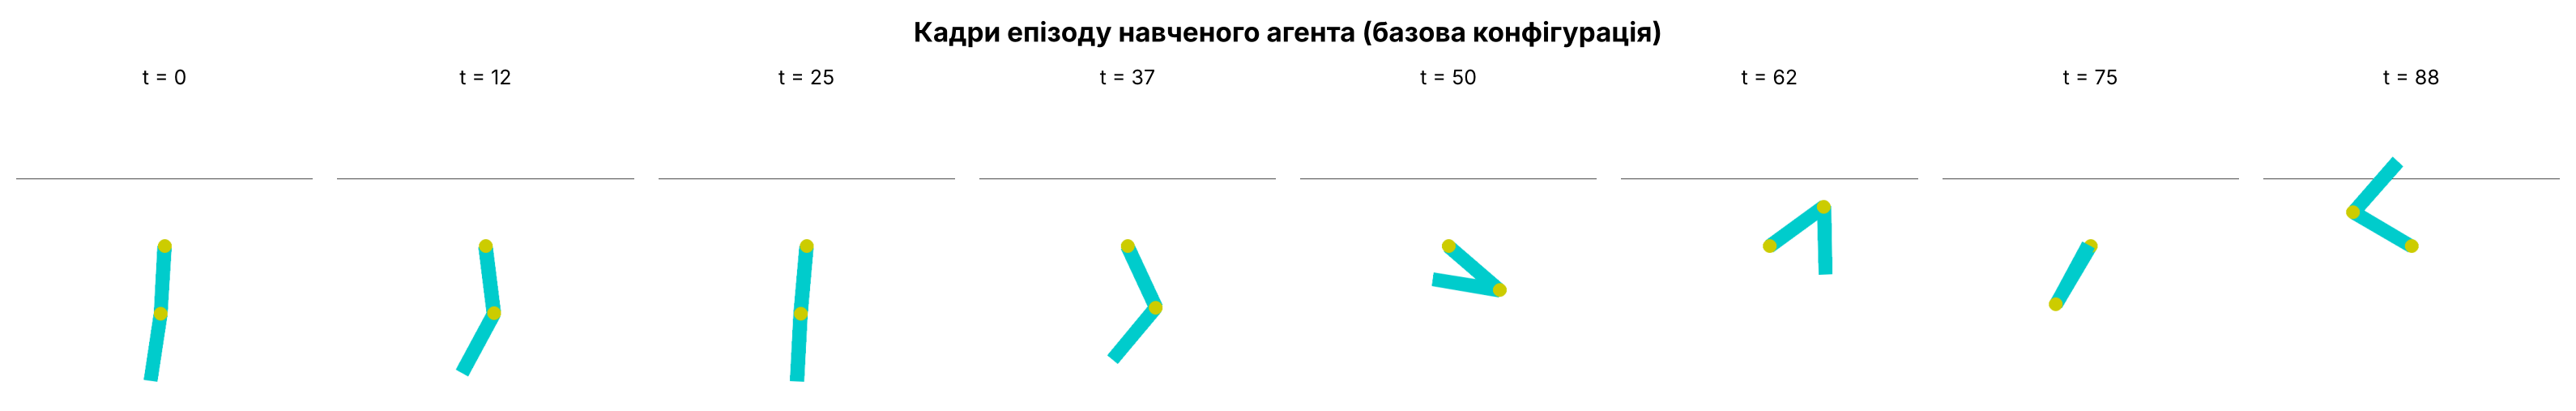

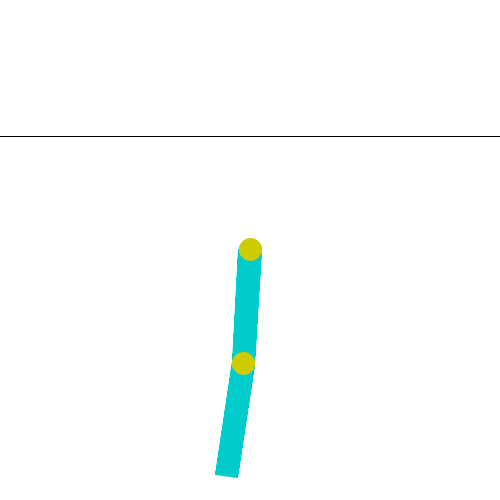

In [10]:
model = DQN.load(f"{ROOT}/base_s0/model.zip", device="cpu")
env_r = gym.make("Acrobot-v1", render_mode="rgb_array")
obs, _ = env_r.reset(seed=50_000)
frames, heights, actions, qs = [env_r.render()], [], [], []
done = False
while not done:
    with torch.no_grad():
        q = model.q_net(torch.as_tensor(obs, dtype=torch.float32)[None]).numpy()[0]
    a = int(np.argmax(q)); qs.append(q); actions.append(a)
    c1, s1, c2, s2 = obs[:4]
    heights.append(-c1 - (c1 * c2 - s1 * s2))          # -cosθ1 - cos(θ1+θ2)
    obs, r, term, trunc, _ = env_r.step(a); done = term or trunc
    frames.append(env_r.render())
c1, s1, c2, s2 = obs[:4]; heights.append(-c1 - (c1 * c2 - s1 * s2))   # висота після останнього кроку
print(f"Епізод завершено за {len(actions)} кроків (дохід {-len(actions) + 1 if term else -len(actions)}), ціль досягнута: {term}")

import imageio
imageio.mimsave("acrobot_dqn_base.gif", frames[::2], fps=15, loop=0)
idx = np.linspace(0, len(frames) - 1, 8).astype(int)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, idx):
    ax.imshow(frames[i]); ax.axis('off'); ax.set_title(f"t = {i}", fontsize=9)
plt.suptitle("Кадри епізоду навченого агента (базова конфігурація)", fontweight="bold")
plt.tight_layout(); plt.savefig("fig_frames.png", dpi=110, bbox_inches="tight"); plt.show()
Image("acrobot_dqn_base.gif")

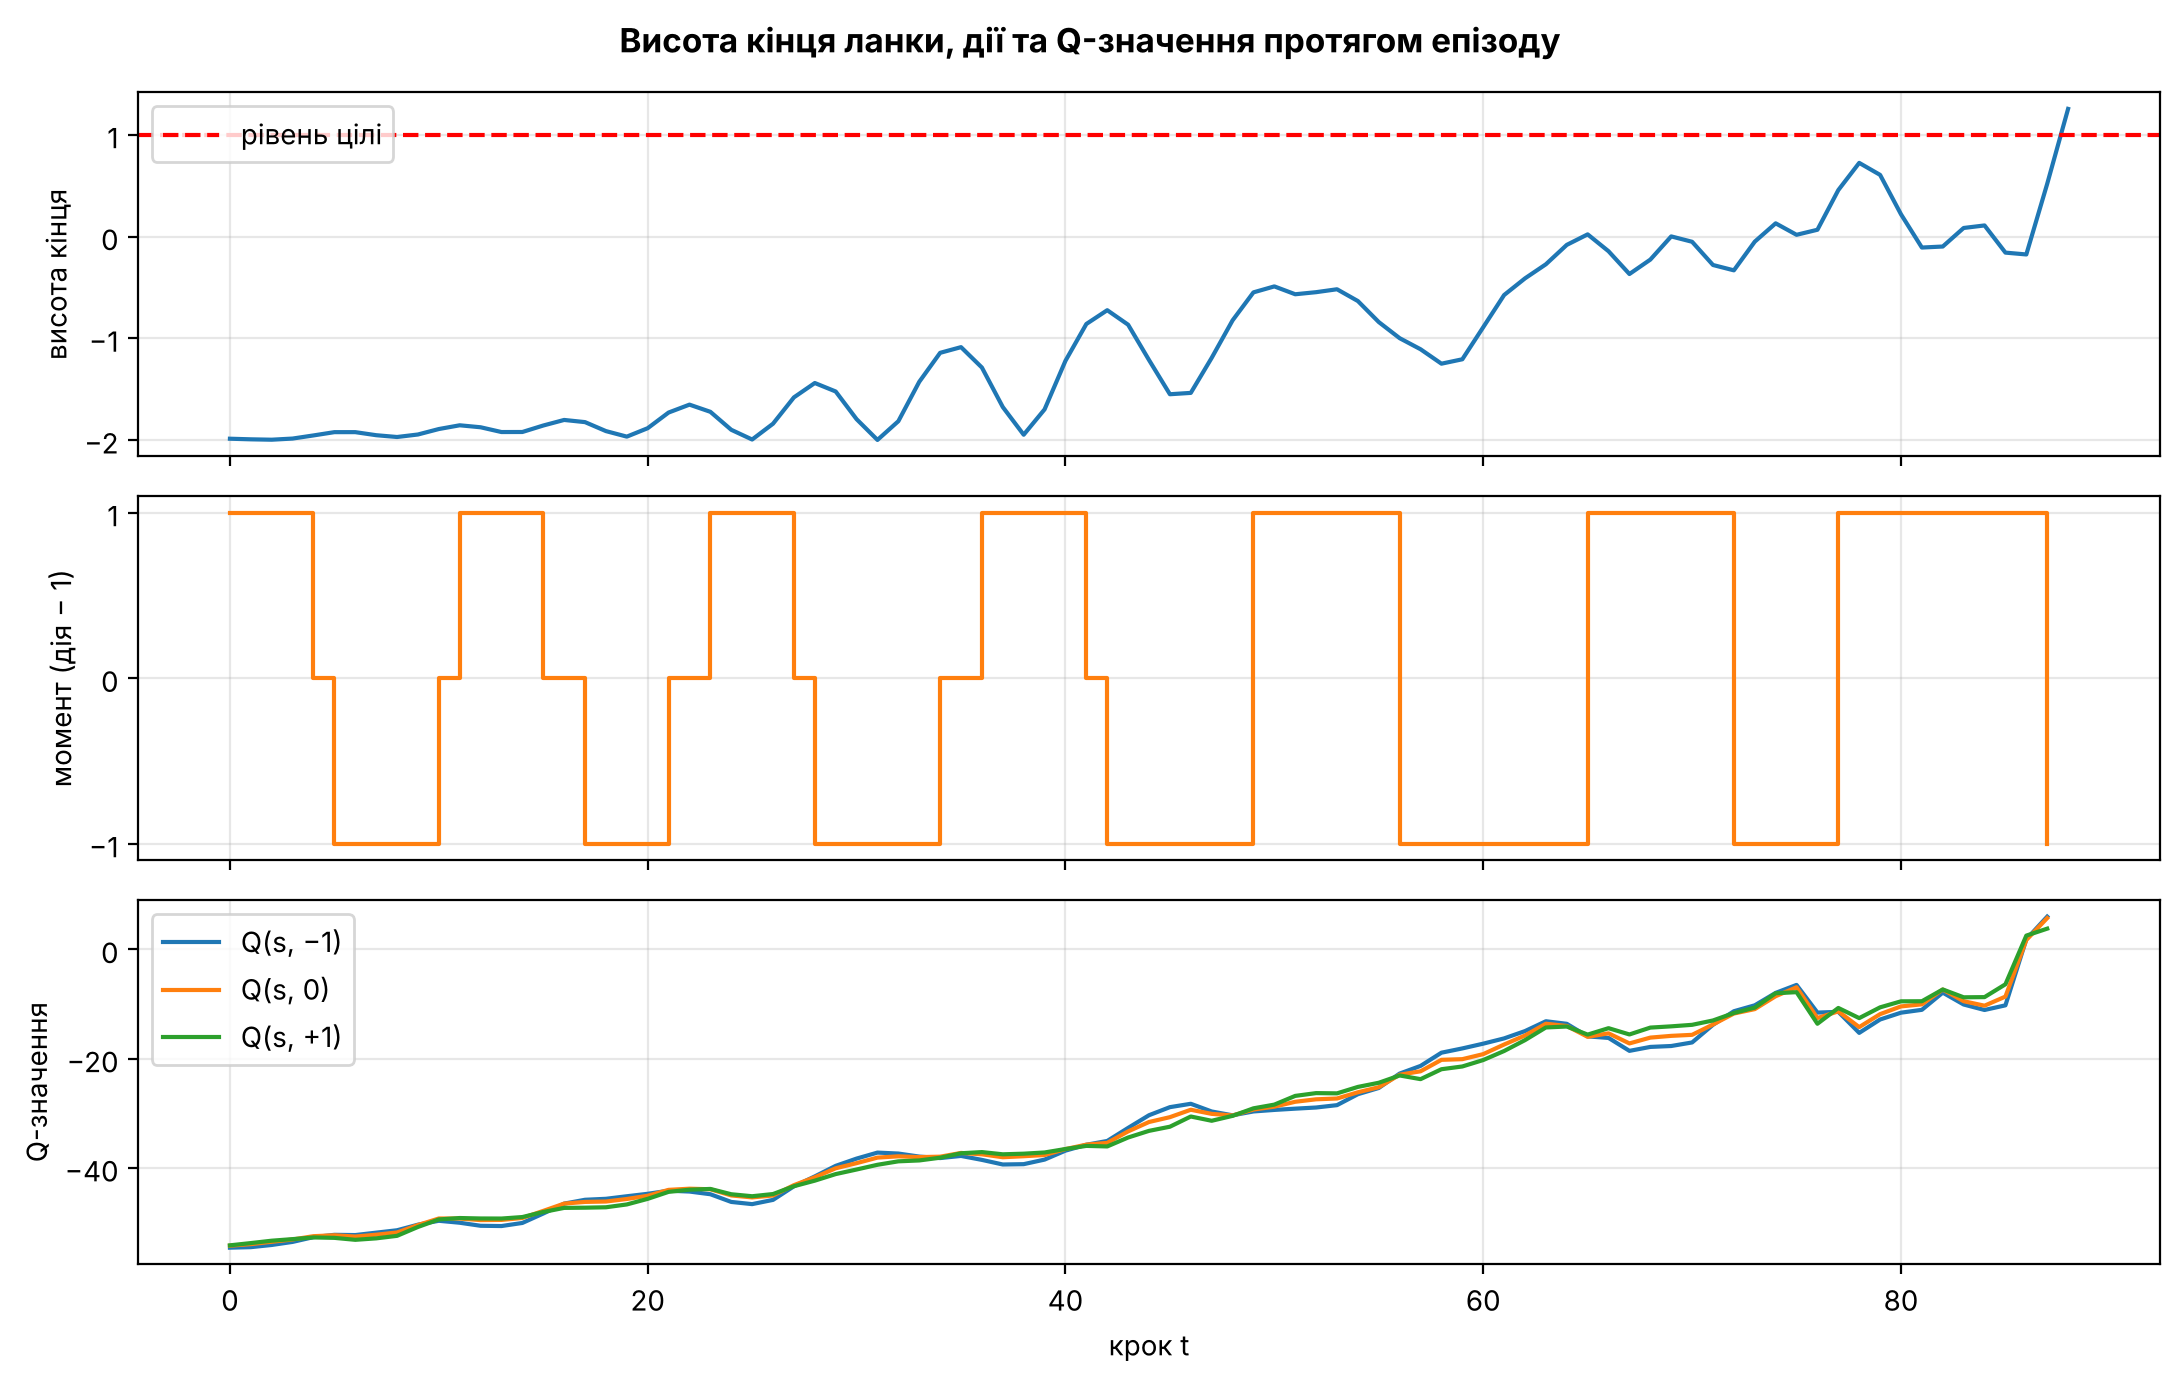

Середній «action gap» (Q найкращої − Q другої дії) = 0.607 при середньому |max Q| = 30.5 (відношення 1.99%)
Частоти дій: {'−1': '42%', '0': '11%', '+1': '47%'}
max Q(s0) = -54.2;  фактичний дисконтований «дохід» з s0 ≈ −(1−γ^T)/(1−γ) = -58.7


In [11]:
qs = np.array(qs); t = np.arange(len(actions))
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(np.arange(len(heights)), heights, color="C0"); axes[0].axhline(1.0, color='r', ls='--', label="рівень цілі")
axes[0].set_ylabel("висота кінця"); axes[0].legend(loc="upper left")
axes[1].step(t, np.array(actions) - 1, where="post", color="C1"); axes[1].set_yticks([-1, 0, 1])
axes[1].set_ylabel("момент (дія − 1)")
for a, lbl in enumerate(["−1", "0", "+1"]):
    axes[2].plot(t, qs[:, a], label=f"Q(s, {lbl})")
axes[2].set_ylabel("Q-значення"); axes[2].set_xlabel("крок t"); axes[2].legend(loc="upper left")
for ax in axes: ax.grid(alpha=.3)
plt.suptitle("Висота кінця ланки, дії та Q-значення протягом епізоду", fontweight="bold")
plt.tight_layout(); plt.savefig("fig_episode.png", dpi=130, bbox_inches="tight"); plt.show()
srt = np.sort(qs, axis=1)
print(f"Середній «action gap» (Q найкращої − Q другої дії) = {np.mean(srt[:, 2] - srt[:, 1]):.3f} "
      f"при середньому |max Q| = {np.mean(np.abs(srt[:, 2])):.1f} (відношення {np.mean(srt[:, 2] - srt[:, 1]) / np.mean(np.abs(srt[:, 2])):.2%})")
print("Частоти дій:", {lbl: f"{np.mean(np.array(actions) == a):.0%}" for a, lbl in enumerate(["−1", "0", "+1"])})
print(f"max Q(s0) = {qs[0].max():.1f};  фактичний дисконтований «дохід» з s0 ≈ −(1−γ^T)/(1−γ) = "
      f"{-(1 - 0.99 ** len(actions)) / (1 - 0.99):.1f}")

## 6. Аналіз і висновки

**Базова конфігурація.** DQN з гіперпараметрами RL Zoo за 60 000 кроків стабільно розв'язує Acrobot: фінальний дохід $-78.0\pm2.7$ (3 seed), 100 % тестових епізодів досягають цілі, поріг $-100$ перетинається в середньому на ~30 000 кроці. Для порівняння, модель RL Zoo, навчена 100 000 кроків, має $-72.1\pm6.4$; випадкова політика — $-500$. Навчений агент керує в режимі «bang-bang»: майже завжди моменти $\pm1$ (дія 0 — лише ~11 % кроків), які чергуються синхронно з рухом маятника і поступово «накачують» енергію. Амплітуда коливань зростає, і на 88-му кроці кінець ланки перетинає рівень цілі.

**Крок навчання.** У діапазоні $10^{-4}$–$3\cdot10^{-3}$ усі варіанти навчаються (−83…−77): Adam, функція Хубера та обрізання градієнта роблять DQN доволі стійким до `learning_rate`. Більший крок швидше досягає порогу (22 тис. кроків проти 25–30 тис.), але сильніше коливається наприкінці (σ оцінок 35 проти 19). Менший крок повільніший і дає дещо гірший фінальний результат за обмежений бюджет.

**Цільова мережа.** Це найчутливіший гіперпараметр. При `target_update_interval=10` ціль майже не «заморожена»: агент навчається найшвидше на початку (поріг на ~20 тис. кроків), але оцінки найнестабільніші (σ = 85, різкі провали кривих). При 2000 за 60 000 кроків відбулося лише 30 оновлень цілі. Кожне оновлення фактично дає один крок «наближеної value iteration», і цього не вистачає, щоб інформація про ціль поширилася на горизонт ~80–100 кроків. Підсумок: −499, жоден seed не досяг порогу. Базове значення 250 — компроміс між стабільністю цілі та швидкістю поширення цінностей.

**Архітектура.** Мережа [64, 64] (4.8 тис. параметрів, у 14 разів менше за базову) не поступається базовій (−80.0), досягає порогу найшвидше (14 тис. кроків), найстабільніша наприкінці (σ = 11) і рахується вдвічі швидше. Отже, [256, 256] для цієї задачі надлишкова. Мережа [16] (163 параметри) нестійка: у 2 з 3 запусків детермінована політика деградує до −500, хоча на проміжних етапах досягала порогу.

**Дослідження.** Довша фаза дослідження (`exploration_fraction=0.5`) уповільнює навчання на початку (більше випадкових дій) і дає −96 (один seed −134). Менший фінальний $\varepsilon=0.01$ дав один частково невдалий запуск (−246): за малого дослідження буфер заповнюють майже однакові траєкторії, і помилки Q-мережі в рідко відвідуваних станах не виправляються. Базове $\varepsilon=0.1$ виявилося найнадійнішим.

**Механізм невдач — малий «action gap».** Діагностика показує, що в усіх невдалих запусках жадібна політика вироджується в *одну дію в усіх станах* (постійний момент, 91–100 % кроків), тому маятник не розгойдується. У навченого агента різниця між Q найкращої і другої дії в середньому становить лише ~2 % від величини $|Q|$ (0.6 проти ~30). Мережа має точно передати велику спільну цінність стану і водночас малу різницю між діями. Мала мережа або застаріла ціль цю різницю «губить». Під час навчання ε-шум частково маскує дефект (навчальні криві −150…−250), але детерміноване оцінювання його виявляє. Звідси практичний висновок: якість DQN слід оцінювати детерміновано, на багатьох епізодах і кількох seed — один успішний епізод чи навчальна крива не показові.

**Q-значення.** $\max_aQ(s_0,a)=-54.2$ проти фактичного дисконтованого доходу −58.7 для епізоду з 88 кроків — розумне наближення з невеликою переоцінкою, характерною для DQN (зміщення через $\max$ у цілі).

**Обмеження дослідження.** 3 seed на конфігурацію (відмінності на рівні кількох одиниць доходу статистично не значущі; надійно встановлено лише явні невдачі); бюджет 60 000 кроків замість 100 000 (повільні варіанти могли б «дозріти»); проміжні оцінки за 10 епізодами шумні; змінювався лише один гіперпараметр за раз, без їх взаємодій; одне середовище; час навчання вимірювався за паралельного завантаження CPU.

## Контрольні запитання (коротко)

1. **Off-policy:** ціль $\max_{a'}Q_{\theta^-}$ відповідає жадібній політиці, а дані збирає ε-жадібна; тому можна вчитися на старих переходах із буфера.
2. **Model-free:** модель переходів не використовується, лише переходи з середовища.
3. **Value-based:** навчається $Q_\theta$, політика — жадібна за $Q$, окремої мережі політики немає.
4. 6 неперервних чисел (cos/sin кутів і кутові швидкості), тип `Box(6,)` float32.
5. 3 дискретні дії — момент −1/0/+1 у середньому шарнірі.
6. −1 за крок до досягнення цілі; заохочує дійти до цілі якомога швидше.
7. `terminated` — досягнуто висоти > 1 (справжній кінець, майбутня цінність 0); `truncated` — 500 кроків (штучне обрізання, майбутня цінність не нуль).
8. Q-net (вхід: стан, вихід: 3 Q-значення) і її копія — цільова мережа.
9. Базова: 6→256→256→3, ReLU у прихованих шарах, лінійний вихід; досліджено [16] і [64, 64].
10. ε-жадібно: ε від 1 до 0.1; під час оцінювання — детерміновано (жадібно).
11. Переходи з буфера відтворення; повторне використання можливе завдяки off-policy цілі.
12. Хуберівська втрата між $Q_\theta(s,a)$ і ціллю $y$; градієнтний крок Adam, обрізання норми градієнта, періодичне копіювання ваг у цільову мережу.
13. `learning_rate`, `buffer_size`, `batch_size`, `gamma`, `target_update_interval`, `train_freq`/`gradient_steps`, `exploration_*`, `net_arch`, `learning_starts`.
14–18. Див. розділи 4–6 та звіт PDF.